# Supplemental Figure 5, Panel G

Heatmaps showing accessibility gains at IFNg and Dex-responsive cREs. Separated into elements that significantly gain accessibility at 1h and 6h, at 1h only, or at 6h only

*Outputs: ifn_1h_hm.pdf, ifn_6h_hm.pdf, ifn_both_hm.pdf, dex_1h_hm.pdf, dex_6h_hm.pdf, dex_both_hm.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(edgeR)
library(ggrastr)
library(gridExtra)
library(RColorBrewer)
library(patchwork)
library(pheatmap)
library(rtracklayer)
library(GenomicRanges)
library(here)
here::i_am("figures/SuppFig5/PanelG/PanelG.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

hm <- function(table, rows, color, n, scale="row"){
    temp <- table[rows,]
    names <- colnames(temp)
    pheatmap(log2(temp+1), cluster_rows=FALSE, cluster_cols=FALSE, color=colorRampPalette(c("white", color))(100), scale=scale , show_rownames=FALSE, cellheight = 150/n,
             breaks=seq(-2,2,length.out=100), 
             main=paste("n=", length(rows)))
}

dex_col <- "#5791c9"
ifn_col <- "#149e77"


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: limma


Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine


Loading required package: GenomicRanges

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following object is masked from ‘package:gridExtra’:

    combine


The following object is masked from ‘package:limma’:

    plotMA


The following objects are masked from ‘package:lub

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2           rtracklayer_1.58.0   GenomicRanges_1.50.2
 [4] GenomeInfoDb_1.34.9  IRanges_2.32.0       S4Vectors_0.36.2    
 [7] BiocGenerics_0.44.0  pheatmap_1.0.12      patchwork_1.3.0     
[10] RColorBrewer_1.1-3   gridExtra_2.3        ggrastr_1.0.2       
[13] edg

# Load data

In [2]:
#read in counts data
countmat_1h <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/countmat/GM12878_stimulus/GM_stim_1h_counts_1.tsv", header=F, sep='\t')
countmat_6h <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/countmat/GM12878_stimulus/GM_stim_6h_counts_1.tsv", header=F, sep='\t')

#read in row metadata
row_meta <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/bed/ATAC_peaks/filtered/consensus_filt_annot.tsv", sep='\t')

#read in column metadata
col_meta_1h <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/countmat/GM12878_stimulus/metadata.txt", sep='\t')
col_meta_6h <- col_meta_1h

#read in differential accessibility results
dar_IFN_1h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/GM12878_stimulus/DAR_IFN_1h.tsv", sep='\t')
dar_IFN_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/GM12878_stimulus/DAR_IFN_6h.tsv", sep='\t')
dar_Dex_1h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/GM12878_stimulus/DAR_Dex_1h.tsv", sep='\t')
dar_Dex_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/GM12878_stimulus/DAR_Dex_6h.tsv", sep='\t')
# read in counts data
countmat_1h <- read.delim(
  here("inputs", "countmat", "GM12878_stimulus", "GM_stim_1h_counts_1.tsv"),
  header = FALSE,
  sep = "\t"
)

countmat_6h <- read.delim(
  here("inputs", "countmat", "GM12878_stimulus", "GM_stim_6h_counts_1.tsv"),
  header = FALSE,
  sep = "\t"
)

# read in row metadata
row_meta <- read.delim(
  here("inputs", "bed", "ATAC_peaks", "filtered", "consensus_filt_annot.tsv"),
  sep = "\t"
)

# read in column metadata
col_meta_1h <- read.delim(
  here("inputs", "countmat", "GM12878_stimulus", "metadata.txt"),
  sep = "\t"
)

col_meta_6h <- col_meta_1h

# filter to only include counts (exclude genomic coordinates)
counts_1h <- countmat_1h[, 5:16]
counts_6h <- countmat_6h[, 5:16]

# load differential accessibility analysis results
dar_IFN_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_1h.tsv"),
  sep = "\t"
)

dar_IFN_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_6h.tsv"),
  sep = "\t"
)

dar_Dex_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_1h.tsv"),
  sep = "\t"
)

dar_Dex_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_6h.tsv"),
  sep = "\t"
)
#filter to only include counts (exclude genomic coordinates)
counts_1h <- countmat_1h[,5:16]
counts_6h <- countmat_6h[,5:16]

#convert to CPM
cpm_1h <- apply(counts_1h, 2, FUN=function(x) 1000000*x/sum(x)) 
cpm_6h <- apply(counts_6h, 2, FUN=function(x) 1000000*x/sum(x)) 

# Define 1h, 6h, and both-timepoint induced sets, and order each set based on induction magnitude

In [3]:
ifn_up_both <- which(dar_IFN_1h$change == "up" & dar_IFN_6h$change == "up")
ifn_up_1h <- which(dar_IFN_1h$change == "up" & dar_IFN_6h$change != "up")
ifn_up_6h <-  which(dar_IFN_1h$change != "up" & dar_IFN_6h$change == "up")

n_ifn <- sum(dar_IFN_1h$change == "up" | dar_IFN_6h$change == "up")
ifn_up_both_ordered <- (dar_IFN_1h[ifn_up_both,] %>% mutate(rownum=ifn_up_both) %>% arrange(desc((logFC*logCPM)-logCPM)))$rownum
ifn_up_1h_ordered <- (dar_IFN_1h[ifn_up_1h,] %>% mutate(rownum=ifn_up_1h) %>% arrange(desc((logFC*logCPM)-logCPM)))$rownum
ifn_up_6h_ordered <- (dar_IFN_6h[ifn_up_6h,] %>% mutate(rownum=ifn_up_6h) %>% arrange(desc((logFC*logCPM)-logCPM)))$rownum

dex_up_both <- which(dar_Dex_1h$change == "up" & dar_Dex_6h$change == "up")
dex_up_1h <- which(dar_Dex_1h$change == "up" & dar_Dex_6h$change != "up")
dex_up_6h <-  which(dar_Dex_1h$change != "up" & dar_Dex_6h$change == "up")

n_dex <- sum(dar_Dex_1h$change == "up" | dar_Dex_6h$change == "up")

dex_up_both_ordered <- (dar_Dex_1h[dex_up_both,] %>% mutate(rownum=dex_up_both) %>% arrange(desc((logFC*logCPM)-logCPM)))$rownum
dex_up_1h_ordered <- (dar_Dex_1h[dex_up_1h,] %>% mutate(rownum=dex_up_1h) %>% arrange(desc((logFC*logCPM)-logCPM)))$rownum
dex_up_6h_ordered <- (dar_Dex_6h[dex_up_6h,] %>% mutate(rownum=dex_up_6h) %>% arrange(desc((logFC*logCPM)-logCPM)))$rownum

# Generate plots

pdf 
  3

pdf 
  3

pdf 
  3

pdf 
  3

pdf 
  3

pdf 
  3

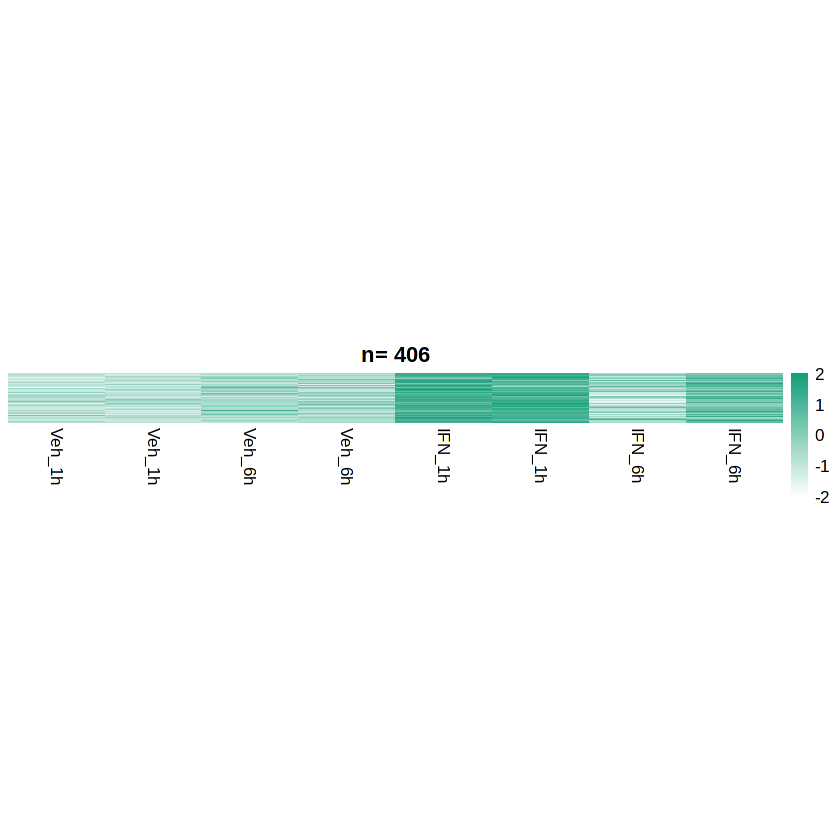

In [4]:
#IFNg
cpm_ifn_all <- cbind(cpm_1h[,1:2],cpm_6h[,1:2], cpm_1h[,3:4],cpm_6h[,3:4]) %>% 
    `colnames<-`(c(rep("Veh_1h",2),rep("Veh_6h",2),rep("IFN_1h",2), rep("IFN_6h",2)))

dev.off()
pdf("ifn_1h_hm.pdf", width=2)
hm(cpm_ifn_all,ifn_up_1h_ordered, ifn_col, n=n_ifn, scale="row")
dev.off()

pdf("ifn_both_hm.pdf", width=2)
hm(cpm_ifn_all,ifn_up_both_ordered, ifn_col, n=n_ifn, scale="row")
dev.off()

pdf("ifn_6h_hm.pdf", width=2)
hm(cpm_ifn_all,ifn_up_6h_ordered, ifn_col, n=n_ifn, scale="row")
dev.off()

#Dex
cpm_dex_all <- cbind(cpm_1h[,1:2],cpm_6h[,1:2], cpm_1h[,5:6],cpm_6h[,5:6]) %>% 
    `colnames<-`(c(rep("Veh_1h",2),rep("Veh_6h",2),rep("Dex_1h",2), rep("Dex_6h",2)))


pdf("dex_1h_hm.pdf", width=2)
hm(cpm_dex_all,dex_up_1h_ordered, dex_col, n=n_dex, scale="row")
dev.off()
pdf("dex_both_hm.pdf", width=2)
hm(cpm_dex_all,dex_up_both_ordered, dex_col, n=n_dex, scale="row")
dev.off()
pdf("dex_6h_hm.pdf", width=2)
hm(cpm_dex_all,dex_up_6h_ordered, dex_col,n=n_dex, scale="row")
dev.off()

In [5]:

dev.off()
pdf("ifn_1h_hm.pdf", width=2)
hm(cpm_ifn_all,ifn_up_1h_ordered, ifn_col, n=n_ifn, scale="row")
dev.off()

pdf 
  3

pdf 
  3